In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arch import arch_model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Libraries imported successfully!")

Project root: C:\Users\ibrah\RPDA8412 Research Project
Libraries imported successfully!


In [3]:
file_path = (
    DATA_DIR
    / "processed"
    / "daily_volatility_engineered_provisional.csv"
)

if not file_path.exists():
    file_path = (
        DATA_DIR
        / "final"
        / "daily_volatility_engineered_provisional.csv"
    )

assert file_path.exists(), (
    f"Cannot find dataset: {file_path}"
)

df = pd.read_csv(
    file_path,
    parse_dates=["Date"]
)

df = (
    df.sort_values("Date")
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["Date"].min())
print(df["Date"].max())

display(df.head())

Dataset shape: (4024, 15)

Available columns:
['Date', 'Adj_Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'GPR_lag1', 'EPU_lag1', 'Log_Return', 'Squared_Return', 'RV_Historical_20D', 'RV_Future_1D', 'RV_Future_5D', 'RV_Future_20D']

Date range:
2010-01-04 00:00:00
2025-12-31 00:00:00


,Date,Adj_Close,Close,High,Low,Open,Volume,GPR_lag1,EPU_lag1,Log_Return,Squared_Return,RV_Historical_20D,RV_Future_1D,RV_Future_5D,RV_Future_20D
0,2010-01-04,1132.989990,1132.989990,1133.869995,1116.560059,1116.560059,3991400000,91.471298,216.95,NaN,NaN,NaN,0.003111,0.006103,0.046068
1,2010-01-05,1136.520020,1136.520020,1136.630005,1129.660034,1132.660034,2491020000,177.117065,150.35,0.003111,9.677276e-06,NaN,0.000545,0.010789,0.046290
2,2010-01-06,1137.140015,1137.140015,1139.189941,1133.949951,1135.709961,4972660000,122.525620,151.16,0.000545,2.974305e-07,NaN,0.003993,0.013596,0.056065
3,2010-01-07,1141.689941,1141.689941,1142.459961,1131.319946,1136.270020,5270680000,161.588669,95.95,0.003993,1.594579e-05,NaN,0.002878,0.013221,0.055997
4,2010-01-08,1144.979980,1144.979980,1145.390015,1136.219971,1140.520020,4389590000,102.262291,92.20,0.002878,8.280484e-06,NaN,0.001745,0.016880,0.056627


In [4]:
print("Return-related columns:")

for column in df.columns:
    if (
        "return" in column.lower()
        or "volatility" in column.lower()
        or "rv_" in column.lower()
    ):
        print(column)

Return-related columns:
Log_Return
Squared_Return
RV_Historical_20D
RV_Future_1D
RV_Future_5D
RV_Future_20D


In [5]:
RETURN_COLUMN = "Log_Return"
TARGET_COLUMN = "RV_Future_20D"

assert RETURN_COLUMN in df.columns, (
    f"Missing return column: {RETURN_COLUMN}"
)

assert TARGET_COLUMN in df.columns, (
    f"Missing target column: {TARGET_COLUMN}"
)

garch_df = df[
    ["Date", RETURN_COLUMN, TARGET_COLUMN]
].copy()

garch_df = (
    garch_df
    .dropna(subset=[RETURN_COLUMN])
    .sort_values("Date")
    .reset_index(drop=True)
)

garch_df["Return_Percent"] = (
    garch_df[RETURN_COLUMN] * 100
)

print("GARCH dataset shape:", garch_df.shape)

display(garch_df.head())

GARCH dataset shape: (4023, 4)


,Date,Log_Return,RV_Future_20D,Return_Percent
0,2010-01-05,0.003111,0.046290,0.311083
1,2010-01-06,0.000545,0.056065,0.054537
2,2010-01-07,0.003993,0.055997,0.399322
3,2010-01-08,0.002878,0.056627,0.287758
4,2010-01-11,0.001745,0.058064,0.174523


In [6]:
reference_path = (
    TABLES_DIR
    / "walk_forward_linear_regression_predictions.csv"
)

assert reference_path.exists(), (
    "Notebook 13 prediction file not found."
)

reference = pd.read_csv(
    reference_path,
    parse_dates=["Date"]
)

validation_dates = reference["Date"].copy()

print(
    "Validation observations:",
    len(validation_dates)
)

print(
    "First validation date:",
    validation_dates.min()
)

print(
    "Last validation date:",
    validation_dates.max()
)

assert len(validation_dates) == 756

assert validation_dates.is_unique

print("Validation dates verified!")

Validation observations: 756
First validation date: 2020-01-02 00:00:00
Last validation date: 2022-12-30 00:00:00
Validation dates verified!


In [7]:
check = reference[
    ["Date", "Actual"]
].merge(
    garch_df[
        ["Date", TARGET_COLUMN]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

assert check[TARGET_COLUMN].notna().all()

assert np.allclose(
    check["Actual"],
    check[TARGET_COLUMN],
    rtol=1e-8,
    atol=1e-10
), "Target values do not match Notebook 13."

print("All 756 target values match Notebook 13!")

All 756 target values match Notebook 13!


In [8]:
def fit_and_forecast_garch(
    returns_percent,
    horizon=20
):
    model = arch_model(
        returns_percent,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fitted = model.fit(
        disp="off",
        show_warning=False
    )

    forecast = fitted.forecast(
        horizon=horizon,
        reindex=False
    )

    forecast_variances = (
        forecast.variance.iloc[-1]
        .to_numpy(dtype=float)
    )

    mu = float(fitted.params["mu"])

    predicted_rv = (
        np.sqrt(
            np.sum(
                forecast_variances + mu**2
            )
        )
        / 100
    )

    return {
        "Predicted": predicted_rv,
        "Mu": mu,
        "Omega": float(fitted.params["omega"]),
        "Alpha": float(fitted.params["alpha[1]"]),
        "Beta": float(fitted.params["beta[1]"]),
        "Convergence_Flag": int(
            fitted.convergence_flag
        )
    }

In [9]:
first_date = validation_dates.iloc[0]

training_returns = garch_df.loc[
    garch_df["Date"] <= first_date,
    "Return_Percent"
]

print("Forecast date:", first_date)

print(
    "Historical return observations:",
    len(training_returns)
)

first_forecast = fit_and_forecast_garch(
    returns_percent=training_returns,
    horizon=20
)

print("\nGARCH forecast:")
print(first_forecast)

Forecast date: 2020-01-02 00:00:00
Historical return observations: 2516

GARCH forecast:
{'Predicted': np.float64(0.03297483181019368), 'Mu': 0.07939638505381981, 'Omega': 0.0369445835743507, 'Alpha': 0.17121646184487616, 'Beta': 0.7896869764825754, 'Convergence_Flag': 0}


In [10]:
assert np.isfinite(
    first_forecast["Predicted"]
)

assert first_forecast["Predicted"] > 0

assert first_forecast["Convergence_Flag"] == 0, (
    "GARCH optimisation did not converge."
)

alpha = first_forecast["Alpha"]
beta = first_forecast["Beta"]

print("Alpha:", alpha)
print("Beta:", beta)
print("Alpha + Beta:", alpha + beta)

print("\nFirst GARCH forecast verified!")

Alpha: 0.17121646184487616
Beta: 0.7896869764825754
Alpha + Beta: 0.9609034383274515

First GARCH forecast verified!


In [11]:
def expanding_window_garch(
    data,
    forecast_dates,
    return_column="Return_Percent",
    horizon=20
):
    results = []

    for count, forecast_date in enumerate(
        forecast_dates,
        start=1
    ):

        train = data.loc[
            data["Date"] <= forecast_date,
            return_column
        ].dropna()

        output = fit_and_forecast_garch(
            returns_percent=train,
            horizon=horizon
        )

        results.append({
            "Date": forecast_date,
            "Predicted": output["Predicted"],
            "Training_Observations": len(train),
            "Mu": output["Mu"],
            "Omega": output["Omega"],
            "Alpha": output["Alpha"],
            "Beta": output["Beta"],
            "Convergence_Flag": output[
                "Convergence_Flag"
            ]
        })

        print(
            f"Completed {count}/{len(forecast_dates)}: "
            f"{forecast_date.date()}"
        )

    return pd.DataFrame(results)

In [12]:
sample_dates = validation_dates.iloc[:10]

start_time = time.time()

garch_sample = expanding_window_garch(
    data=garch_df,
    forecast_dates=sample_dates,
    horizon=20
)

print(
    "\nElapsed time:",
    round(time.time() - start_time, 2),
    "seconds"
)

display(garch_sample)

Completed 1/10: 2020-01-02
Completed 2/10: 2020-01-03
Completed 3/10: 2020-01-06
Completed 4/10: 2020-01-07
Completed 5/10: 2020-01-08
Completed 6/10: 2020-01-09
Completed 7/10: 2020-01-10
Completed 8/10: 2020-01-13
Completed 9/10: 2020-01-14
Completed 10/10: 2020-01-15

Elapsed time: 0.15 seconds


,Date,Predicted,Training_Observations,Mu,Omega,Alpha,Beta,Convergence_Flag
0,2020-01-02,0.032975,2516,0.079396,0.036945,0.171216,0.789687,0
1,2020-01-03,0.034374,2517,0.078953,0.037014,0.171294,0.789559,0
2,2020-01-06,0.033504,2518,0.079049,0.036933,0.171066,0.789809,0
3,2020-01-07,0.033002,2519,0.078885,0.036874,0.170927,0.789965,0
4,2020-01-08,0.032747,2520,0.079080,0.036832,0.170895,0.790022,0
5,2020-01-09,0.033184,2521,0.079383,0.036831,0.170931,0.789994,0
6,2020-01-10,0.032758,2522,0.079245,0.036780,0.170837,0.790105,0
7,2020-01-13,0.033330,2523,0.079560,0.036786,0.170882,0.790065,0
8,2020-01-14,0.032575,2524,0.079505,0.036720,0.170766,0.790203,0
9,2020-01-15,0.031807,2525,0.079602,0.036653,0.170747,0.790263,0


In [13]:
assert len(garch_sample) == 10

assert garch_sample["Date"].equals(
    sample_dates.reset_index(drop=True)
)

assert (
    garch_sample["Predicted"] > 0
).all()

assert np.isfinite(
    garch_sample["Predicted"]
).all()

assert (
    garch_sample["Convergence_Flag"] == 0
).all()

assert (
    garch_sample["Training_Observations"]
    .diff()
    .dropna()
    >= 0
).all()

print("All GARCH walk-forward sample checks passed!")

All GARCH walk-forward sample checks passed!


In [14]:
start_time = time.time()

garch_walk_forward = expanding_window_garch(
    data=garch_df,
    forecast_dates=validation_dates,
    horizon=20
)

elapsed_minutes = (time.time() - start_time) / 60

print("\nFull GARCH walk-forward completed!")
print(f"Time taken: {elapsed_minutes:.2f} minutes")

print("Forecasts generated:", len(garch_walk_forward))

display(garch_walk_forward.head())
display(garch_walk_forward.tail())

Completed 1/756: 2020-01-02
Completed 2/756: 2020-01-03
Completed 3/756: 2020-01-06
Completed 4/756: 2020-01-07
Completed 5/756: 2020-01-08
Completed 6/756: 2020-01-09
Completed 7/756: 2020-01-10
Completed 8/756: 2020-01-13
Completed 9/756: 2020-01-14
Completed 10/756: 2020-01-15
Completed 11/756: 2020-01-16
Completed 12/756: 2020-01-17
Completed 13/756: 2020-01-21
Completed 14/756: 2020-01-22
Completed 15/756: 2020-01-23
Completed 16/756: 2020-01-24
Completed 17/756: 2020-01-27
Completed 18/756: 2020-01-28
Completed 19/756: 2020-01-29
Completed 20/756: 2020-01-30
Completed 21/756: 2020-01-31
Completed 22/756: 2020-02-03
Completed 23/756: 2020-02-04
Completed 24/756: 2020-02-05
Completed 25/756: 2020-02-06
Completed 26/756: 2020-02-07
Completed 27/756: 2020-02-10
Completed 28/756: 2020-02-11
Completed 29/756: 2020-02-12
Completed 30/756: 2020-02-13
Completed 31/756: 2020-02-14
Completed 32/756: 2020-02-18
Completed 33/756: 2020-02-19
Completed 34/756: 2020-02-20
Completed 35/756: 2020-

,Date,Predicted,Training_Observations,Mu,Omega,Alpha,Beta,Convergence_Flag
0,2020-01-02,0.032975,2516,0.079396,0.036945,0.171216,0.789687,0
1,2020-01-03,0.034374,2517,0.078953,0.037014,0.171294,0.789559,0
2,2020-01-06,0.033504,2518,0.079049,0.036933,0.171066,0.789809,0
3,2020-01-07,0.033002,2519,0.078885,0.036874,0.170927,0.789965,0
4,2020-01-08,0.032747,2520,0.079080,0.036832,0.170895,0.790022,0


,Date,Predicted,Training_Observations,Mu,Omega,Alpha,Beta,Convergence_Flag
751,2022-12-23,0.053266,3267,0.077348,0.036982,0.180932,0.792570,0
752,2022-12-27,0.049976,3268,0.077267,0.037014,0.180858,0.792528,0
753,2022-12-28,0.051330,3269,0.077105,0.036989,0.180822,0.792612,0
754,2022-12-29,0.055261,3270,0.077380,0.036951,0.180931,0.792657,0
755,2022-12-30,0.051321,3271,0.077326,0.036959,0.180732,0.792736,0


In [15]:
print("Total forecasts:", len(garch_walk_forward))

print(
    "Successful convergence:",
    (garch_walk_forward["Convergence_Flag"] == 0).sum()
)

print(
    "Failed convergence:",
    (garch_walk_forward["Convergence_Flag"] != 0).sum()
)

print(
    "Minimum prediction:",
    garch_walk_forward["Predicted"].min()
)

print(
    "Maximum prediction:",
    garch_walk_forward["Predicted"].max()
)

assert len(garch_walk_forward) == 756

assert garch_walk_forward["Date"].is_unique

assert garch_walk_forward["Date"].equals(
    validation_dates.reset_index(drop=True)
)

assert np.isfinite(
    garch_walk_forward["Predicted"]
).all()

assert (
    garch_walk_forward["Predicted"] > 0
).all()

print("\nBasic GARCH checks passed!")

Total forecasts: 756
Successful convergence: 756
Failed convergence: 0
Minimum prediction: 0.030924972517895322
Maximum prediction: 0.30859364323960203

Basic GARCH checks passed!


In [16]:
garch_results = reference[
    ["Date", "Actual"]
].merge(
    garch_walk_forward,
    on="Date",
    how="left",
    validate="one_to_one"
)

assert len(garch_results) == 756

assert garch_results["Predicted"].notna().all()

display(garch_results.head())

print("Actual and predicted values aligned!")

,Date,Actual,Predicted,Training_Observations,Mu,Omega,Alpha,Beta,Convergence_Flag
0,2020-01-02,0.032513,0.032975,2516,0.079396,0.036945,0.171216,0.789687,0
1,2020-01-03,0.032545,0.034374,2517,0.078953,0.037014,0.171294,0.789559,0
2,2020-01-06,0.035606,0.033504,2518,0.079049,0.036933,0.171066,0.789809,0
3,2020-01-07,0.037217,0.033002,2519,0.078885,0.036874,0.170927,0.789965,0
4,2020-01-08,0.037043,0.032747,2520,0.079080,0.036832,0.170895,0.790022,0


Actual and predicted values aligned!


In [17]:
def evaluate_garch(y_true, y_pred, epsilon=1e-4):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    safe_mape = np.mean(
        np.abs(y_true - y_pred)
        / np.maximum(np.abs(y_true), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }


garch_wf_metrics = evaluate_garch(
    garch_results["Actual"],
    garch_results["Predicted"]
)

print("=" * 60)
print("EXPANDING-WINDOW GARCH(1,1) RESULTS")
print("=" * 60)

for metric, value in garch_wf_metrics.items():
    print(f"{metric}: {value:.6f}")

EXPANDING-WINDOW GARCH(1,1) RESULTS
RMSE: 0.035096
MAE: 0.019588
Safe_MAPE: 31.316152


In [18]:
garch_comparison = pd.DataFrame([
    {
        "Model": "GARCH Fixed Parameters",
        "RMSE": 0.034771,
        "MAE": 0.019197,
        "Safe_MAPE": 29.495222
    },
    {
        "Model": "GARCH Expanding Window",
        **garch_wf_metrics
    },
    {
        "Model": "Linear Regression Walk-Forward",
        "RMSE": 0.036248,
        "MAE": 0.019111,
        "Safe_MAPE": 28.795058
    },
    {
        "Model": "XGBoost Walk-Forward",
        "RMSE": 0.038990,
        "MAE": 0.020457,
        "Safe_MAPE": 29.151002
    },
    {
        "Model": "Random Forest Walk-Forward",
        "RMSE": 0.039358,
        "MAE": 0.020407,
        "Safe_MAPE": 29.056783
    },
    {
        "Model": "Persistence",
        "RMSE": 0.043013,
        "MAE": 0.023945,
        "Safe_MAPE": 37.751981
    }
])

garch_comparison = (
    garch_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(garch_comparison.round(6))

,Model,RMSE,MAE,Safe_MAPE
0,GARCH Fixed Parameters,0.034771,0.019197,29.495222
1,GARCH Expanding Window,0.035096,0.019588,31.316152
2,Linear Regression Walk-Forward,0.036248,0.019111,28.795058
3,XGBoost Walk-Forward,0.038990,0.020457,29.151002
4,Random Forest Walk-Forward,0.039358,0.020407,29.056783
5,Persistence,0.043013,0.023945,37.751981


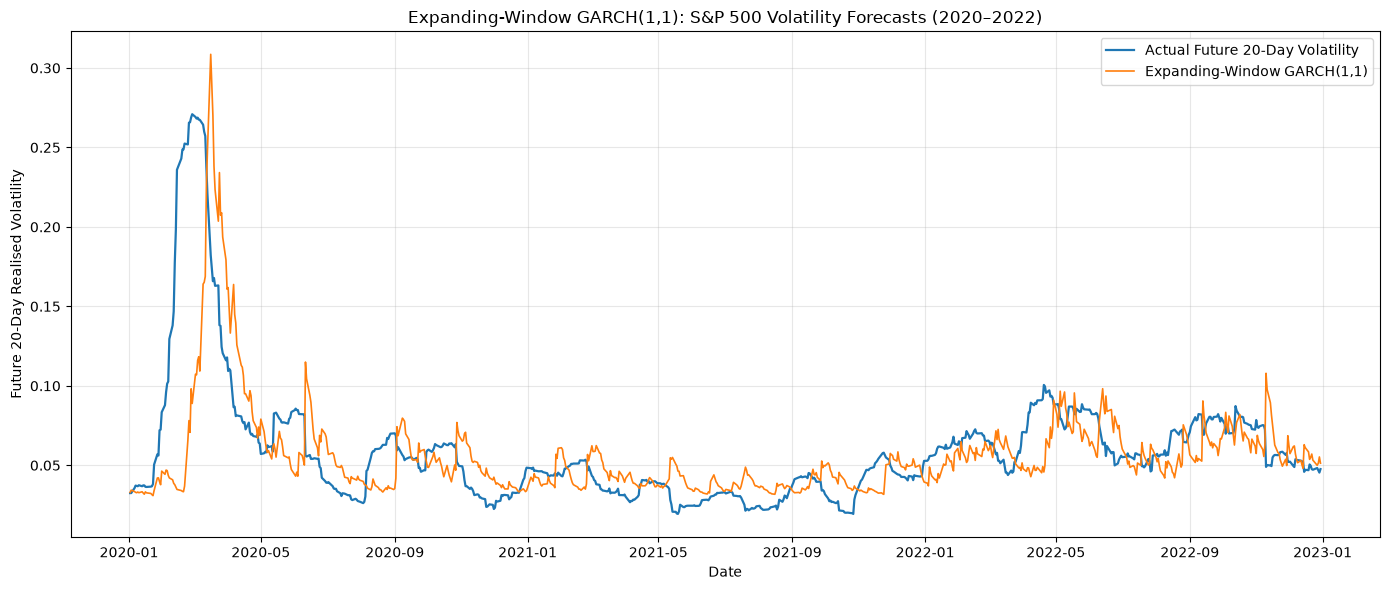

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    garch_results["Date"],
    garch_results["Actual"],
    label="Actual Future 20-Day Volatility",
    linewidth=1.6
)

plt.plot(
    garch_results["Date"],
    garch_results["Predicted"],
    label="Expanding-Window GARCH(1,1)",
    linewidth=1.2
)

plt.title(
    "Expanding-Window GARCH(1,1): "
    "S&P 500 Volatility Forecasts (2020–2022)"
)

plt.xlabel("Date")
plt.ylabel("Future 20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "garch_walk_forward_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
garch_results.to_csv(
    TABLES_DIR / "garch_walk_forward_predictions.csv",
    index=False
)

garch_comparison.to_csv(
    TABLES_DIR / "garch_walk_forward_comparison.csv",
    index=False
)

print("GARCH predictions saved!")
print("Model comparison saved!")

GARCH predictions saved!
Model comparison saved!


In [21]:
convergence_summary = (
    garch_results["Convergence_Flag"]
    .value_counts()
    .sort_index()
)

print("=" * 55)
print("GARCH CONVERGENCE SUMMARY")
print("=" * 55)

print(convergence_summary)

successful = (
    garch_results["Convergence_Flag"] == 0
).sum()

failed = (
    garch_results["Convergence_Flag"] != 0
).sum()

print("\nSuccessful fits:", successful)
print("Failed fits:", failed)

print("\nAlpha + Beta summary:")

garch_results["Persistence"] = (
    garch_results["Alpha"]
    + garch_results["Beta"]
)

print(
    garch_results["Persistence"].describe()
)

GARCH CONVERGENCE SUMMARY
Convergence_Flag
0    756
Name: count, dtype: int64

Successful fits: 756
Failed fits: 0

Alpha + Beta summary:
count    756.000000
mean       0.967477
std        0.002877
min        0.960129
25%        0.965753
50%        0.967875
75%        0.969382
max        0.973856
Name: Persistence, dtype: float64
